<a href="https://colab.research.google.com/github/gmatheushq/IntCienciaDeDados/blob/main/gas_brazil_logistica_versao2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preços de combustíveis no Brasil (2004–2021): análise e classificação

**O que este notebook faz:** limpa a base da ANP, descreve os preços *por produto e unidade de medida* e treina uma Regressão Logística para prever se o preço de revenda está **acima da mediana nacional do próprio produto naquele ano**.

Principais correções em relação à versão anterior: sem vazamento de dados, sem mistura de unidades, textos normalizados (OLEO/ÓLEO), divisão treino/teste por tempo e pipeline do scikit-learn.

## 1. Importações e carregamento do arquivo

In [5]:
import os
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ARQUIVO = "2004-2021.tsv"

try:
    from google.colab import files
    if not os.path.exists(ARQUIVO):
        print(f"Selecione o arquivo '{ARQUIVO}':")
        enviado = files.upload()
        ARQUIVO = list(enviado.keys())[0]
except ImportError:
    pass

print("Arquivo a ser lido:", ARQUIVO)

Arquivo a ser lido: 2004-2021.tsv


## 2. Leitura do bsnco de dados

In [10]:
def ler_tabela(caminho):
    erros = []
    for codificacao in ("utf-8", "latin1"):
        try:
            return pd.read_csv(caminho, sep="\t", encoding=codificacao)
        except (UnicodeDecodeError, pd.errors.ParserError) as e:
            erros.append(f"{codificacao}: {e}")
    raise RuntimeError("Não foi possível ler o arquivo:\n" + "\n".join(erros))


df = ler_tabela(ARQUIVO)
print(f"concluido {df.shape}")

concluido (120823, 18)


## 3. Limpeza e padronização

In [9]:
def sem_acento(texto):
    """remove todos os acentos (á, â, ã, í, õ, ç...)"""
    nfkd = unicodedata.normalize("NFKD", texto)
    return "".join(c for c in nfkd if not unicodedata.combining(c))


#padronizar nome das colunas
df.columns = [
    sem_acento(c).strip().lower().replace(" ", "_").replace("-", "_")
    for c in df.columns
]

#colunas esperadas
PRECO = "preco_medio_revenda" #def coluna de preço medio
OBRIGATORIAS = [PRECO, "produto", "unidade_de_medida", "data_final"]
faltando = [c for c in OBRIGATORIAS if c not in df.columns]
assert not faltando, f"Colunas ausentes na base: {faltando}. Colunas existentes: {list(df.columns)}"

#remove duplicadas
antes = len(df)
df = df.drop_duplicates()
print(f"Linhas duplicadas removidas: {antes - len(df)}")

# data
colunas_data = [c for c in df.columns if c.startswith("data")]
for col in colunas_data:
    convertida = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")
    if convertida.isna().all():
        convertida = pd.to_datetime(df[col], dayfirst=True, errors="coerce")
    df[col] = convertida

#padroniza as colunas que recebe variaveis de texto
COLUNAS_TEXTO = [
    c for c in df.columns
    if c not in colunas_data and not pd.api.types.is_numeric_dtype(df[c])
]
for col in COLUNAS_TEXTO:
    df[col] = df[col].map(
        lambda x: sem_acento(str(x)).strip().upper() if pd.notna(x) else np.nan
    )
    df[col] = df[col].replace({"": np.nan, "NAN": np.nan, "NONE": np.nan})

#coluna numerica coloca no padrao brasileiro
def para_numero(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return serie
    s = serie.astype(str).str.replace("R$", "", regex=False).str.strip()
    tem_virgula = s.str.contains(",", regex=False)
    s = s.where(~tem_virgula, s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    return pd.to_numeric(s, errors="coerce")

COLUNAS_NUMERICAS = [c for c in df.columns if c not in colunas_data and c not in COLUNAS_TEXTO]
#colunas de texto que, na verdade, são números (preços lidos como texto)
for col in list(COLUNAS_TEXTO):
    if any(t in col for t in ["preco", "desvio", "margem", "coeficiente", "coef", "numero"]):
        df[col] = para_numero(df[col])
        COLUNAS_TEXTO.remove(col)
        COLUNAS_NUMERICAS.append(col)

# preço remove ausentes e valores negativos
antes = len(df)
df = df[df[PRECO].notna() & (df[PRECO] > 0)].reset_index(drop=True)
print(f"Linhas removidas por preço ausente/inválido: {antes - len(df)}")

#variaveis de tempo
df["ano"] = df["data_final"].dt.year
df["mes"] = df["data_final"].dt.month
df = df.dropna(subset=["ano"]).reset_index(drop=True)
df[["ano", "mes"]] = df[["ano", "mes"]].astype(int)

print(f"\nLimpeza concluída {df.shape[0]} linhas e {df.shape[1]} colunas.")
print("Produtos encontrados:", sorted(df["produto"].dropna().unique()))
print("Unidades encontradas:", sorted(df["unidade_de_medida"].dropna().unique()))

Linhas duplicadas removidas: 0
Linhas removidas por preço ausente/inválido: 0

Limpeza concluída 120823 linhas e 20 colunas.
Produtos encontrados: ['ETANOL HIDRATADO', 'GASOLINA ADITIVADA', 'GASOLINA COMUM', 'GLP', 'GNV', 'OLEO DIESEL', 'OLEO DIESEL S10']
Unidades encontradas: ['R$/13KG', 'R$/L', 'R$/M3']


## 4. Análise exploratória (sempre separada por produto/unidade)

 1. PREÇO DE REVENDA POR PRODUTO E UNIDADE DE MEDIDA 
                                      registros  media  mediana  desvio  minimo  maximo
produto            unidade_de_medida                                                   
ETANOL HIDRATADO   R$/L                   23440   2.44     2.28    0.74    0.77    5.96
GASOLINA ADITIVADA R$/L                     749   5.05     4.94    0.51    3.85    6.68
GASOLINA COMUM     R$/L                   23570   3.20     2.87    0.77    1.89    6.69
GLP                R$/13KG                23561  47.66    41.37   15.93   28.03  107.50
GNV                R$/M3                  14469   2.03     1.85    0.65    0.98    4.78
OLEO DIESEL        R$/L                   23545   2.55     2.29    0.71    1.31    5.85
OLEO DIESEL S10    R$/L                   11489   3.27     3.26    0.53    2.13    5.86


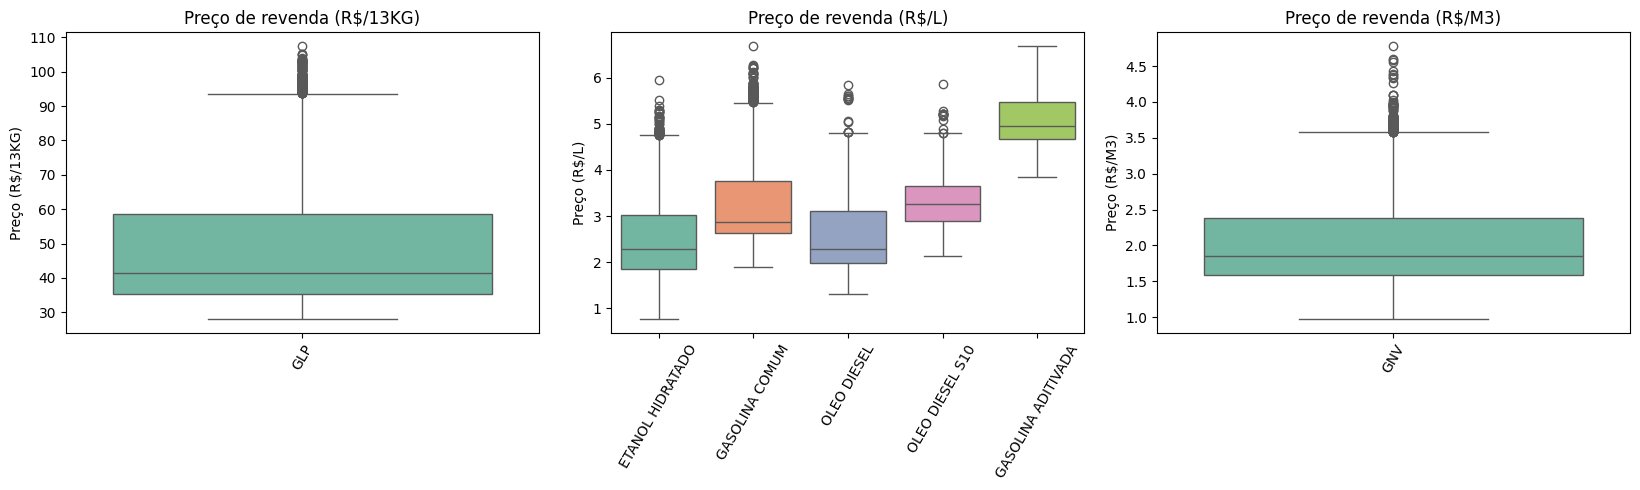

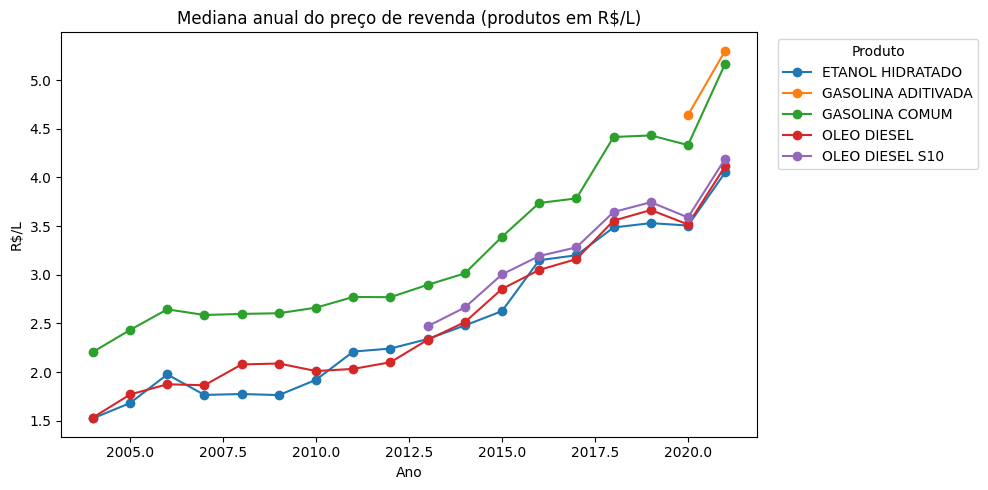

In [ ]:
print("=" * 60)
print(" 1. PREÇO DE REVENDA POR PRODUTO E UNIDADE DE MEDIDA ")
print("=" * 60)

resumo = (
    df.groupby(["produto", "unidade_de_medida"])[PRECO]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .round(2)
      .rename(columns={"count": "registros", "mean": "media", "median": "mediana",
                       "std": "desvio", "min": "minimo", "max": "maximo"})
)
print(resumo.to_string())

# Gráfico 1: um boxplot por unidade de medida (cada escala em seu próprio painel)
unidades = sorted(df["unidade_de_medida"].dropna().unique())
fig, eixos = plt.subplots(1, len(unidades), figsize=(5.5 * len(unidades), 5), squeeze=False)
for ax, un in zip(eixos[0], unidades):
    sub = df[df["unidade_de_medida"] == un]
    sns.boxplot(data=sub, x="produto", y=PRECO, hue="produto",
                palette="Set2", legend=False, ax=ax)
    ax.set_title(f"Preço de revenda ({un})")
    ax.set_xlabel("")
    ax.set_ylabel(f"Preço ({un})")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

# Gráfico 2: evolução da mediana anual dos produtos vendidos em R$/L
litros = df[df["unidade_de_medida"] == "R$/L"]
if not litros.empty:
    evolucao = litros.groupby(["ano", "produto"])[PRECO].median().unstack()
    evolucao.plot(figsize=(10, 5), marker="o")
    plt.title("Mediana anual do preço de revenda (produtos em R$/L)")
    plt.xlabel("Ano")
    plt.ylabel("R$/L")
    plt.legend(title="Produto", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## 5. Variável-alvo e escolha das variáveis (sem vazamento)

* **Alvo:** `preco_alto = 1` se o preço da linha é maior que a **mediana nacional do mesmo produto no mesmo ano**; caso contrário, `0`. Assim, GLP (R$/botijão) e gasolina (R$/L) são comparados apenas com seus pares, e a inflação não domina o problema.
* **Variáveis excluídas (vazamento):** todas as estatísticas de revenda (mínimo, máximo, desvio, coeficiente de variação) e a margem, que são calculadas a partir do próprio preço. Os preços de distribuição também ficam de fora por padrão (`INCLUIR_DISTRIBUICAO = False`).

In [ ]:
INCLUIR_DISTRIBUICAO = False   # mude para True se quiser testar com preços de distribuição

# 5.1 Alvo: preço acima da mediana do produto no ano
mediana_produto_ano = df.groupby(["produto", "ano"])[PRECO].transform("median")
df["preco_alto"] = (df[PRECO] > mediana_produto_ano).astype(int)
print("Distribuição do alvo (%):")
print((df["preco_alto"].value_counts(normalize=True) * 100).round(1))

# 5.2 Colunas que NÃO podem entrar no modelo
vazamento = {c for c in df.columns if ("revenda" in c) or ("margem" in c)}   # inclui o próprio PRECO
if not INCLUIR_DISTRIBUICAO:
    vazamento |= {c for c in df.columns if "distribuicao" in c}

EXCLUIR = vazamento | set(colunas_data) | {"preco_alto", "ano", "unidade_de_medida"}
# "unidade_de_medida" é redundante (cada produto tem uma unidade); "ano" é excluído porque
# o teste fica em anos posteriores ao treino e o modelo não deve extrapolar a tendência.

# 5.3 Variáveis de entrada
colunas_cat = [c for c in df.columns
               if c not in EXCLUIR
               and not pd.api.types.is_numeric_dtype(df[c])
               and df[c].nunique() <= 100]
colunas_num = [c for c in df.columns
               if c not in EXCLUIR and pd.api.types.is_numeric_dtype(df[c])]

print("\nVariáveis categóricas:", colunas_cat)
print("Variáveis numéricas:  ", colunas_num)
print("Colunas excluídas por vazamento:", sorted(vazamento))

# 5.4 Divisão temporal: treino = 80% mais antigo, teste = 20% mais recente
data_corte = df["data_final"].quantile(0.80)
treino = df[df["data_final"] <= data_corte]
teste = df[df["data_final"] > data_corte]

X_train, y_train = treino[colunas_cat + colunas_num], treino["preco_alto"]
X_test, y_test = teste[colunas_cat + colunas_num], teste["preco_alto"]

print(f"\nTreino: {len(treino)} linhas ({treino['data_final'].min().date()} a {treino['data_final'].max().date()})")
print(f"Teste:  {len(teste)} linhas ({teste['data_final'].min().date()} a {teste['data_final'].max().date()})")
print(f"Proporção de preço alto no teste: {y_test.mean():.1%}")

Distribuição do alvo (%):
preco_alto
0    50.2
1    49.8
Name: proportion, dtype: float64

Variáveis categóricas: ['regiao', 'estado', 'produto']
Variáveis numéricas:   ['numero_de_postos_pesquisados', 'mes']
Colunas excluídas por vazamento: ['coef_de_variacao_distribuicao', 'coef_de_variacao_revenda', 'desvio_padrao_distribuicao', 'desvio_padrao_revenda', 'margem_media_revenda', 'preco_maximo_distribuicao', 'preco_maximo_revenda', 'preco_medio_distribuicao', 'preco_medio_revenda', 'preco_minimo_distribuicao', 'preco_minimo_revenda']

Treino: 96761 linhas (2004-05-15 a 2018-03-17)
Teste:  24062 linhas (2018-03-24 a 2021-05-01)
Proporção de preço alto no teste: 51.3%


## 6. Modelo: pipeline com pré-processamento, baseline e Regressão Logística

 DESEMPENHO NO CONJUNTO DE TESTE (período mais recente) 
Acurácia do baseline:       48.68%
Acurácia do modelo:         64.38%
Acurácia balanceada:        64.48%
ROC AUC:                    0.712

                        precision    recall  f1-score   support

Abaixo/Igual à mediana       0.62      0.68      0.65     11713
      Acima da mediana       0.67      0.61      0.64     12349

              accuracy                           0.64     24062
             macro avg       0.65      0.64      0.64     24062
          weighted avg       0.65      0.64      0.64     24062



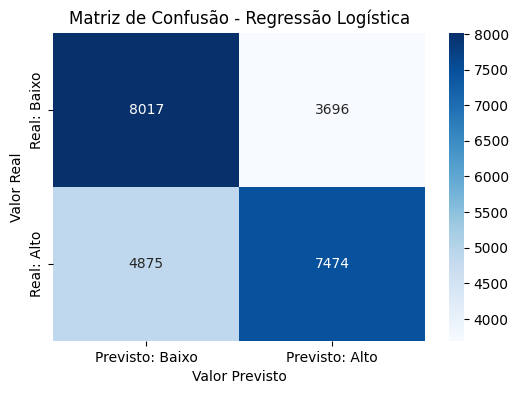

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Todo o pré-processamento fica DENTRO do pipeline: é ajustado só com o treino
preprocessador = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), colunas_num),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), colunas_cat),
])

modelo = Pipeline([
    ("pre", preprocessador),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])
modelo.fit(X_train, y_train)

# Baseline: sempre prever a classe mais frequente (referência mínima a ser superada)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print("=" * 60)
print(" DESEMPENHO NO CONJUNTO DE TESTE (período mais recente) ")
print("=" * 60)
print(f"Acurácia do baseline:       {accuracy_score(y_test, baseline.predict(X_test)):.2%}")
print(f"Acurácia do modelo:         {accuracy_score(y_test, y_pred):.2%}")
print(f"Acurácia balanceada:        {balanced_accuracy_score(y_test, y_pred):.2%}")
print(f"ROC AUC:                    {roc_auc_score(y_test, y_prob):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["Abaixo/Igual à mediana", "Acima da mediana"]))

if accuracy_score(y_test, y_pred) > 0.98:
    print("ATENÇÃO: acurácia próxima de 100% em dados reais é suspeita. "
          "Verifique se alguma coluna derivada do preço entrou nas variáveis de entrada.")

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Previsto: Baixo", "Previsto: Alto"],
            yticklabels=["Real: Baixo", "Real: Alto"])
plt.title("Matriz de Confusão - Regressão Logística")
plt.ylabel("Valor Real")
plt.xlabel("Valor Previsto")
plt.show()

## 7. Coeficientes do modelo

In [ ]:
nomes = modelo.named_steps["pre"].get_feature_names_out()
coeficientes = (
    pd.DataFrame({"Variável": nomes, "Coeficiente": modelo.named_steps["clf"].coef_[0]})
      .sort_values("Coeficiente", ascending=False)
)

print("Top 8 variáveis que MAIS AUMENTAM a chance de o preço ser alto:")
print(coeficientes.head(8).round(3).to_string(index=False))
print("\nTop 8 variáveis que MAIS DIMINUEM a chance de o preço ser alto:")
print(coeficientes.tail(8).round(3).to_string(index=False))

# Observação: os coeficientes indicam associação (não causa) e estão em escala padronizada
# (numéricas) ou são efeitos de cada categoria em relação às demais (one-hot).

Top 8 variáveis que MAIS AUMENTAM a chance de o preço ser alto:
                     Variável  Coeficiente
             cat__estado_ACRE        4.016
            cat__regiao_NORTE        2.015
         cat__estado_RONDONIA        1.450
cat__estado_RIO GRANDE DO SUL        0.803
            cat__estado_PIAUI        0.737
      cat__estado_MATO GROSSO        0.667
          cat__estado_RORAIMA        0.603
             cat__produto_GNV        0.520

Top 8 variáveis que MAIS DIMINUEM a chance de o preço ser alto:
              Variável  Coeficiente
   cat__estado_PARAIBA       -0.948
   cat__regiao_SUDESTE       -1.019
     cat__estado_GOIAS       -1.087
cat__estado_PERNAMBUCO       -1.205
    cat__estado_PARANA       -1.505
 cat__estado_TOCANTINS       -1.580
  cat__estado_AMAZONAS       -1.611
 cat__estado_SAO PAULO       -1.667
